## 다음 영화 리뷰 데이터 분석
1. 데이터 로딩
2. 텍스트 전처리
3. 빈도수 계산
4. 시각화

In [1]:
# 데이터 로딩 
datafile = "data/daum_movie_review.csv"

import pandas as pd
df = pd.read_csv(datafile)
df.head()

,review,rating,date,title
0,돈 들인건 티가 나지만 보는 내내 하품만,1,2018.10.29,인피니티 워
1,몰입할수밖에 없다. 어렵게 생각할 필요없다. 내가 전투에 참여한듯 손에 땀이남.,10,2018.10.26,인피니티 워
2,이전 작품에 비해 더 화려하고 스케일도 커졌지만.... 전국 맛집의 음식들을 한데 ...,8,2018.10.24,인피니티 워
3,이 정도면 볼만하다고 할 수 있음!,8,2018.10.22,인피니티 워
4,재미있다,10,2018.10.20,인피니티 워


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14725 entries, 0 to 14724
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  14725 non-null  object
 1   rating  14725 non-null  int64 
 2   date    14725 non-null  object
 3   title   14725 non-null  object
dtypes: int64(1), object(3)
memory usage: 460.3+ KB


In [3]:
# 품사 태킹 -> 토큰화, 불용어제거
from konlpy.tag import Okt

tagger = Okt()
reviews = list(df.review)

pos_list = []
for reviews in reviews:
    tokens = tagger.pos(reviews)
    pos_list.append(tokens)

len(pos_list)

14725

In [4]:
pos_list[:1]

[[('돈', 'Noun'),
  ('들인건', 'Verb'),
  ('티', 'Noun'),
  ('가', 'Josa'),
  ('나', 'Noun'),
  ('지만', 'Josa'),
  ('보는', 'Verb'),
  ('내내', 'Noun'),
  ('하품', 'Noun'),
  ('만', 'Josa')]]

In [5]:
print(pos_list[:5])

[[('돈', 'Noun'), ('들인건', 'Verb'), ('티', 'Noun'), ('가', 'Josa'), ('나', 'Noun'), ('지만', 'Josa'), ('보는', 'Verb'), ('내내', 'Noun'), ('하품', 'Noun'), ('만', 'Josa')], [('몰입', 'Noun'), ('할수밖에', 'Verb'), ('없다', 'Adjective'), ('.', 'Punctuation'), ('어렵게', 'Adjective'), ('생각', 'Noun'), ('할', 'Verb'), ('필요없다', 'Adjective'), ('.', 'Punctuation'), ('내', 'Noun'), ('가', 'Josa'), ('전투', 'Noun'), ('에', 'Josa'), ('참여', 'Noun'), ('한', 'Determiner'), ('듯', 'Noun'), ('손', 'Noun'), ('에', 'Josa'), ('땀', 'Noun'), ('이남', 'Noun'), ('.', 'Punctuation')], [('이전', 'Noun'), ('작품', 'Noun'), ('에', 'Josa'), ('비해', 'Verb'), ('더', 'Noun'), ('화려하고', 'Adjective'), ('스케일', 'Noun'), ('도', 'Josa'), ('커졌지만', 'Verb'), ('....', 'Punctuation'), ('전국', 'Noun'), ('맛집', 'Noun'), ('의', 'Josa'), ('음식', 'Noun'), ('들', 'Suffix'), ('을', 'Josa'), ('한데', 'Eomi'), ('모은', 'Verb'), ('것', 'Noun'), ('까지는', 'Josa'), ('좋았으나', 'Adjective'), ('이', 'Determiner'), ('걸', 'Noun'), ('모두', 'Noun'), ('한', 'Verb'), ('그릇', 'Noun'), ('에', 'Josa'), ('섞어', 'Ver

In [6]:
# 불용어 제거 -> 필요한 품사의 단어만 추출
my_tags = ['Noun', 'Verb', 'Adjective']
my_stopwords = ['영화', '것', '이', '더']
result_list = []
for reviews in pos_list:
    for word, tag in reviews:
        if tag in my_tags and word not in my_stopwords:
            result_list.append(word)

result_list[:10]

['돈', '들인건', '티', '나', '보는', '내내', '하품', '몰입', '할수밖에', '없다']

In [7]:
# 빈도수 계산 -> Counter 객체르 생성하여 사용
from collections import Counter

counter = Counter(result_list)
count_list = counter.most_common(20)
print(count_list)

[('연기', 1293), ('감동', 1223), ('생각', 1027), ('정말', 948), ('배우', 847), ('사람', 819), ('스토리', 815), ('진짜', 781), ('잘', 776), ('하는', 770), ('눈물', 737), ('보고', 709), ('점', 692), ('최고', 682), ('좀', 671), ('재미', 641), ('마지막', 612), ('그', 610), ('시간', 596), ('입니다', 580)]


In [8]:
#matplotlib 한글폰트 설정
font_path = 'C:/Windows/Fonts/malgun.ttf'

from matplotlib import font_manager, rc
font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)

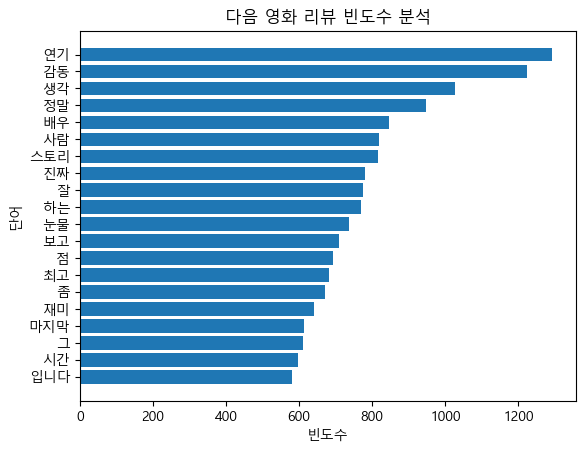

In [9]:
# 시각화 - 수평 막대 그래프
import matplotlib.pyplot as plt

# (1) 데이터 준비
x = [word for word, count in count_list]
y = [count for word, count in count_list]

# x = [], y = []
# for word, count in count_list:
#     x.append(word)
#     y.append(count)

# (2) 그래프 생성
plt.barh(x[::-1], y[::-1])

# (3) 필요 정보 보기
plt.title("다음 영화 리뷰 빈도수 분석")
plt.xlabel('빈도수')
plt.ylabel('단어')


# (4) 출력
#plt.show()
plt.savefig('./result/daum_movie_review_graph.jpg')

In [10]:
# 대한민국 헌법 wordcloud 생성하기
from konlpy.corpus import kolaw
input_filename = 'constitution.txt'
const_doc = kolaw.open(input_filename).read()
len(const_doc), type(const_doc)


(18884, str)

In [19]:
const_doc[:100]

'대한민국헌법\n\n유구한 역사와 전통에 빛나는 우리 대한국민은 3·1운동으로 건립된 대한민국임시정부의 법통과 불의에 항거한 4·19민주이념을 계승하고, 조국의 민주개혁과 평화적 통일의'

In [20]:
# wordcloud 설치
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [21]:
from wordcloud import WordCloud

font_path = 'C:/Windows/Fonts/malgun.ttf'

# WordCloud 클래스의 객체 생성
wc = WordCloud(
    font_path = font_path
)

In [22]:
# 워드클라우드 생성 from 텍스트
wc = wc.generate(const_doc)

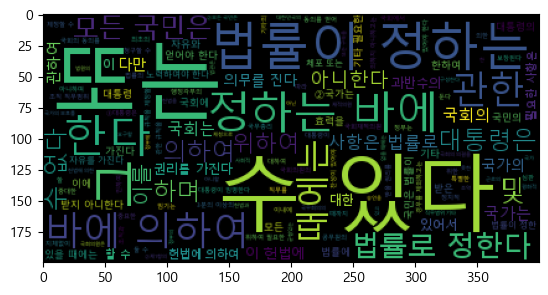

In [23]:
# matplotlib의 pyplot과 연동
import matplotlib.pyplot as plt
plt.imshow(wc)

In [11]:
# 헌법 -> 전처리 -> 빈도수 객체 (Counter)

# 전처리 : 토큰화, 정제, 정규화 -> 품사태깅, 불용어제거
from konlpy.tag import Okt
tagger = Okt().pos

tokens = tagger(const_doc)
tokens[:10]

[('대한민국', 'Noun'),
 ('헌법', 'Noun'),
 ('\n\n', 'Foreign'),
 ('유구', 'Noun'),
 ('한', 'Josa'),
 ('역사', 'Noun'),
 ('와', 'Josa'),
 ('전통', 'Noun'),
 ('에', 'Josa'),
 ('빛나는', 'Verb')]

In [15]:
# 불용어 제거 : 원하는 품사 정의, 삭제할 단어 사전 정의
my_tags = ['Noun']
my_stopwords = []

result_list = [word for word, tag in tokens if tag in my_tags and word not in my_stopwords]
result_list[:10]

['대한민국', '헌법', '유구', '역사', '전통', '우리', '국민', '운동', '건립', '대한민국']

In [18]:
# 빈도수 계산 : Counter 클래스
from collections import Counter
counter = Counter(result_list)

<function matplotlib.pyplot.show(close=None, block=None)>

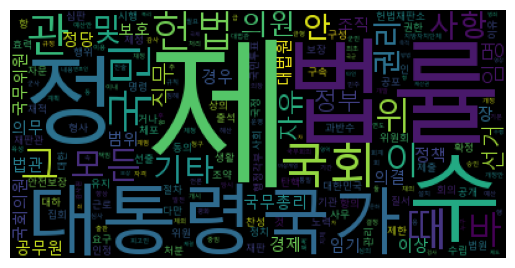

In [24]:
# 워드클라우드 적요
wc = wc.generate_from_frequencies(counter)
plt.imshow(wc)
plt.axis('off')
plt.show